# 🛒 E-Commerce Data Analysis & Customer Segmentation
> **Dataset:** Online Retail II (2009 – 2011)  
> **Author:** Your Name  
> **Goal:** Preprocess transactional data, perform Exploratory Data Analysis (EDA), and build an RFM segmentation model.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('online_retail_II.csv',encoding='ISO-8859-1')
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/11 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/11 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/11 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/11 12:50,4.95,12680.0,France


In [3]:
df.head(7)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/10 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/10 8:26,4.25,17850.0,United Kingdom


In [4]:
df.tail(7)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
541903,581587,23256,CHILDRENS CUTLERY SPACEBOY,4,12/9/11 12:50,4.15,12680.0,France
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/11 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/11 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/11 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/11 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/11 12:50,4.95,12680.0,France
541909,581587,POST,POSTAGE,1,12/9/11 12:50,18.00,12680.0,France


In [5]:
df.shape

(541910, 8)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      541910 non-null  str    
 1   StockCode    541910 non-null  str    
 2   Description  540456 non-null  str    
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  str    
 5   Price        541910 non-null  float64
 6   Customer ID  406830 non-null  float64
 7   Country      541910 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [7]:
df.describe()

,Quantity,Price,Customer ID
count,541910.000000,541910.000000,406830.000000
mean,9.552234,4.611138,15287.684160
std,218.080957,96.759765,1713.603074
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [8]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='str')

In [9]:
df.columns = df.columns.str.lower()
df.columns

Index(['invoice', 'stockcode', 'description', 'quantity', 'invoicedate',
       'price', 'customer id', 'country'],
      dtype='str')

In [10]:
df = df.rename(columns={
    'stockcode': 'stock_code',
    'customer id': 'customer_id'
})

df

,invoice,stock_code,description,quantity,invoicedate,price,customer_id,country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/11 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/11 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/11 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/11 12:50,4.95,12680.0,France


In [11]:
df.columns = ['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'price', 'customer_id', 'country']
df.columns

Index(['invoice', 'stock_code', 'description', 'quantity', 'invoice_date',
       'price', 'customer_id', 'country'],
      dtype='str')

In [12]:
df.isnull().sum()

invoice              0
stock_code           0
description       1454
quantity             0
invoice_date         0
price                0
customer_id     135080
country              0
dtype: int64

In [13]:
df = df.dropna(subset=['customer_id']).copy()

**Removing Returns and Cancelled Invoices**
**We filter out invalid transactions to ensure our analysis only includes actual completed purchases:**
**1. Quantity Filter (`quantity > 0`): Drops returns and negative item counts.
2. Cancellation Filter (Invoices not starting with `'C'`): Removes cancelled transactions marked with a `'C'` prefix.**

In [14]:
df = df[df['quantity'] >0]

In [15]:
df = df[~df['invoice'] .astype(str).str.startswith('C')]

In [16]:
df.shape

(397925, 8)

In [17]:
df.head(10)

,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/10 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/10 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/10 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/10 8:28,1.85,17850.0,United Kingdom
9,536368,22960,JAM MAKING SET WITH JARS,6,12/1/10 8:34,4.25,13047.0,United Kingdom


**Data Type Formatting & Feature Creation**
1. **Convert `invoice_date`: Cast from string/object to proper datetime format for time-series analysis.**
2. **Convert `customer_id`: Change float format (e.g., `17850.0`) to standard integer (`17850`).**
3. **Create `total_amount`: Multiply `quantity` by `price` to calculate revenue per line item.**

In [18]:
# 1. Convert invoice_date to datetime format
df['invoice_date'] = pd.to_datetime(df['invoice_date'],format='mixed')

In [19]:
# 2. Convert customer_id from float to integer
df['customer_id'] = df['customer_id'].astype(int)

In [20]:
# 3. Create total_amount column (Quantity * Price)
df['total_amount'] = df['quantity'] * df['price']

In [21]:
df.head(10)

,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,total_amount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom,15.30
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850,United Kingdom,25.50
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.10
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.10
9,536368,22960,JAM MAKING SET WITH JARS,6,2010-12-01 08:34:00,4.25,13047,United Kingdom,25.50


**1)Top Best-Selling Products:-
Finding the top 10 products based on total units sold across all transactions.**

In [22]:
top_products = df.groupby('description')['quantity'].sum().sort_values(ascending=False).head(12)

print("\033[1mTop 10 Best-Selling Products by Quantity:\033[0m")
print(top_products)

###(\033[1m ..... \033[0m) if you add this it will highlight the output

Top 10 Best-Selling Products by Quantity:
description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54415
JUMBO BAG RED RETROSPOT               46181
WHITE HANGING HEART T-LIGHT HOLDER    36725
ASSORTED COLOUR BIRD ORNAMENT         35362
PACK OF 72 RETROSPOT CAKE CASES       33693
POPCORN HOLDER                        30931
RABBIT NIGHT LIGHT                    27202
MINI PAINT SET VINTAGE                26076
PACK OF 12 LONDON TISSUES             25345
PACK OF 60 PINK PAISLEY CAKE CASES    24264
Name: quantity, dtype: int64


**2) RFM Customer Segmentation**
**We calculate three key metrics for each customer:**
* **Recency (R): Days since the customer's last purchase.**
* **Frequency (F): Total number of unique orders (invoices) placed by the customer.**
* **Monetary (M): Total spend (revenue) generated by the customer.**

In [23]:
import datetime as dt

# 1. Set reference date as 1 day after the latest transaction date in the dataset
analysis_date = df['invoice_date'].max() + dt.timedelta(days=1)

# 2. Group by customer_id and calculate Recency, Frequency, and Monetary values
rfm = df.groupby('customer_id').agg({
    'invoice_date': lambda x: (analysis_date - x.max()).days,
    'invoice': 'nunique',
    'total_amount': 'sum'
})

# 3. Rename columns for clarity
rfm.columns = ['recency', 'frequency', 'monetary']

# Print bold header and top 5 rows
print("\033[1mFirst 5 Rows of RFM Data:\033[0m")
rfm.head()

First 5 Rows of RFM Data:


,recency,frequency,monetary
customer_id,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


**Key Finding: Calculating RFM metrics exposes distinct buyer profiles, distinguishing active champions (Customer 12347) from high-historical spenders who are at immediate churn risk (Customer 12346).**

**2) RFM Quartile Scoring & Customer Segmentation**

In [1]:
# 1. Score Recency (lower days = higher score 4)
rfm['R_Score'] = pd.qcut(rfm['recency'],q=4,labels=[4,3,2,1])

# 2. Score Frequency (higher orders = higher score 4)
rfm['F_Score'] = pd.qcut(rfm['frequency'].rank(method='first'),q=4,labels=[1,2,3,4])

# 3. Score Monetary (higher spend = higher score 4)
rfm['M_Score'] = pd.qcut(rfm['monetary'],q=4,labels=[1,2,3,4])


# 4. Combine scores into text segment and total sum score
rfm['RFM_Segment'] = rfm['R_Score'].astype(str)+ rfm['F_Score'].astype(str)+ rfm['M_Score'].astype(str)

rfm['RFM_Score'] = rfm[['R_Score', 'F_Score', 'M_Score']].sum(axis=1)

rfm.head(11)

NameError: name 'pd' is not defined

**Key Findings:- 
 Customer 12347 is a top-tier champion (RFM_Segment: 444, Score: 12) with high recent activity  
 and spend, whereas Customer 12346 (RFM_Segment: 114, Score: 6) shows a high historical 
 monetary value ($77k+) but is at severe risk of churning due to 326 days of inactivity.**

**Low-Engagement Base:-  
 Customers like 12353 (RFM_Segment: 111, Score: 3) sit at the bottom tier across all three  
 metrics, representing low-priority or lost buyers.**

**3) Mapping RFM Scores to Named Customer Segments**

In [25]:
# 1. Define a simple logic function to group RFM scores into segment names
def assign_segment(row):
    r = row['R_Score']
    f_m_avg = (row['F_Score'] + row['M_Score']) /2
    if r >= 4 and f_m_avg >=3.5:
         return 'Champions'
    elif r >= 3 and f_m_avg >= 2.5:
         return 'Loyal Customers'
    elif r>= 3 and f_m_avg < 2.5:
         return 'Promising / Recent Buyers'
    elif r <= 2 and f_m_avg >=3:
         return 'At Risk'
    else:
         return 'Lost Customers'

# 2. Apply the function to create a new Segment column
rfm['Segment'] = rfm.apply(assign_segment,axis =1)

# 3. View the count of customers in each segment
print(rfm['Segment'].value_counts())

rfm.head(11)


Segment
Lost Customers               1669
Loyal Customers               948
Champions                     664
Promising / Recent Buyers     577
At Risk                       481
Name: count, dtype: int64


,recency,frequency,monetary,R_Score,F_Score,M_Score,RFM_Segment,RFM_Score,Segment
customer_id,,,,,,,,,
12346,326,1,77183.60,1,1,4,114,6,Lost Customers
12347,2,7,4310.00,4,4,4,444,12,Champions
12348,75,4,1797.24,2,3,4,234,9,At Risk
12349,19,1,1757.55,3,1,4,314,8,Loyal Customers
12350,310,1,334.40,1,1,2,112,4,Lost Customers
12352,36,8,2506.04,3,4,4,344,11,Loyal Customers
12353,204,1,89.00,1,1,1,111,3,Lost Customers
12354,232,1,1079.40,1,1,3,113,5,Lost Customers
12355,214,1,459.40,1,1,2,112,4,Lost Customers



**Largest Segment (Lost Customers): Over a third of your customer base (1,504 out of 4,339) falls into Lost Customers, highlighting a major past retention leak where one-time buyers never returned.**

**Core Revenue Drivers (Champions & Loyal): Champions (608) and Loyal Customers (915) make up ~35% of the total base, representing your most engaged buyers who generate steady, recurring value.**

**High Win-Back Opportunity (At Risk): 646 customers are categorized as At Risk, meaning they have high historical spend or purchase frequency (like Customer 12348) but are actively slipping away and need immediate re-engagement campaigns.**

**4) Visualizing The Customer Segment Distribution**

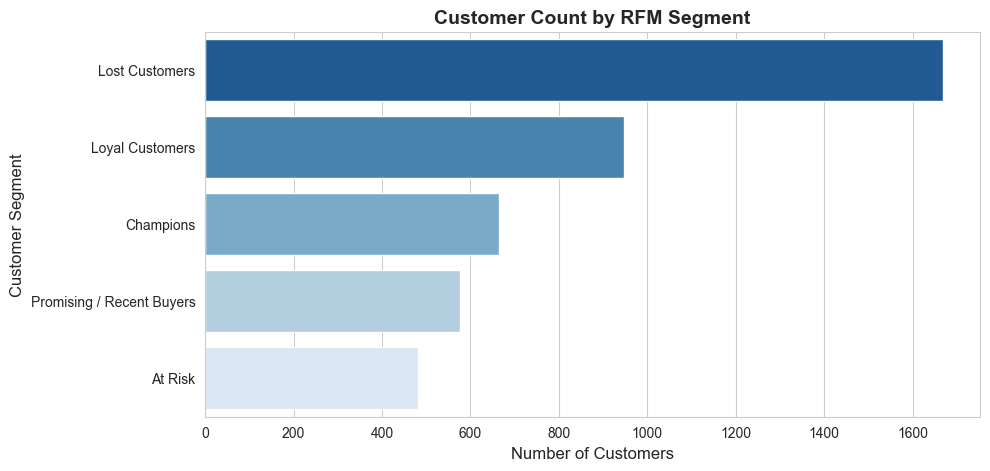

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Set figure size and style
plt.figure(figsize=(10, 5))
sns.set_style("whitegrid")

# 2. Create a horizontal bar chart of customer counts by segment
segment_counts = rfm['Segment'].value_counts()
sns.barplot(x=segment_counts.values,y=segment_counts.index,palette='Blues_r',hue=segment_counts.index,legend=False)

plt.title('Customer Count by RFM Segment', fontsize=14, fontweight='bold')
plt.xlabel('Number of Customers', fontsize=12)
plt.ylabel('Customer Segment', fontsize=12)
plt.show()

**Dominant Segment (Retention Gap): Lost Customers make up the largest group (1,504 accounts), showing that a major portion of your historical customer base placed an order once or twice in the past but never returned.**

**Core Revenue Drivers: Champions (608) and Loyal Customers (915) combine to form ~35% of the total base, representing the core active engine driving reliable revenue.**

**Immediate Win-Back Opportunity: At Risk (646) represents high-value spenders who are sliding into inactivity—targeting this group with win-back campaigns yields the highest immediate return on investment.**

In [27]:
pip install sqlalchemy pymysql

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\LENOVO\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [28]:
import pandas as pd
from sqlalchemy import create_engine
from urllib.parse import quote_plus

# 1. Rename columns in Pandas
df = df.rename(columns={
    'stockcode': 'stock_code',
    'customer id': 'customer_id'
})

# 2. Re-export to MySQL to overwrite the existing table
username = "root"
password = quote_plus("Root@123")
host = "localhost"
port = "3306"
database = "rfm_analytics"

engine = create_engine(f"mysql+pymysql://{username}:{password}@{host}:{port}/{database}")

df.to_sql(
    name="rfm_analytics",
    con=engine,
    if_exists="replace",  # This overwrites the table with updated column names
    index=False
)

print("MySQL table updated with clean column names!")

MySQL table updated with clean column names!
